In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy.stats import bootstrap
from scipy.stats import ttest_ind

from src.src import *

# MT, RT, ST, wait, click

In [2]:
# Remove outliers
# Read in adaptation subject data
df_adapt = pd.read_csv("data/iti-adapt-data.csv")
df_adapt.rename(columns={"fbi": "vis_fb",
                   "rotation": "delta_xv",
                   "theta_maxradv": "x_f"}, 
            inplace=True)
df_adapt["session"] = "adapt"

# Create perturbation variable
num_adapt_trials = np.max(df_adapt["TN"])
pert_trial = np.zeros(num_adapt_trials, dtype="bool")
# every odd trial beginning with Trial Num 101 (idx=100) is pert trial
pert_trial[100::2] = True
pert_trial = np.tile(pert_trial, reps=np.max(df_adapt["SN"]))
df_adapt["pert_trial"] = pert_trial


# Read in pert detection subject data
df_sdt = pd.read_csv("data/iti-sdt-data.csv")
df_sdt.rename(columns={"fbi": "vis_fb",
                       "rotation": "delta_xv",
                       "theta_maxradv": "x_f",
                       "perturbation_responses": "pert_resp"}, 
            inplace=True)
df_sdt["session"] = "sdt"
# Create perturbation variable (defined differently than adapt; every non-zero rotation here)
pert_trial = np.where(np.abs(df_sdt["delta_xv"]) > 0, True, False)
df_sdt["pert_trial"] = pert_trial

In [3]:
# Outlier handling (not "removal")
df_adapt = remove_outliers(3.5,
                                df_adapt,
                                "x_f",
                                "SN",
                                "adapt",
                                abs_cutoff=22.5,
                                switch_outlier_with_mean=False
)

df_sdt = remove_outliers(3.5,
                              df_sdt,
                              "x_f",
                              "SN",
                              "sdt",
                              abs_cutoff=22.5,
                              switch_outlier_with_mean=False
)


# Compute adaptation metric (must be done after replacing outliers with NaNs)
pert_indices = np.flatnonzero(df_adapt["pert_trial"])
adaptation = np.zeros(len(df_adapt))
adaptation[pert_indices] = df_adapt.loc[pert_indices + 1, "x_f_clean"].to_numpy() - df_adapt.loc[pert_indices - 1, "x_f_clean"].to_numpy()
df_adapt["adaptation"] = adaptation

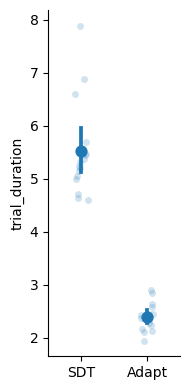

In [4]:
# Trial times = T_last - T_first (first sample is 0 for all but first trial)
df_trial_duration = pd.concat([
    df_sdt.groupby("SN")["trial_duration"].mean().reset_index().assign(Condition="SDT"),
    df_adapt.groupby("SN")["trial_duration"].mean().reset_index().assign(Condition="Adapt")
], ignore_index=True)

plt.figure(figsize=(2, 4))
sns.pointplot(data=df_trial_duration, x="Condition", y="trial_duration", ls="")
sns.stripplot(data=df_trial_duration, x="Condition", y="trial_duration", zorder=0, alpha=0.2)
plt.xlabel("")
plt.tight_layout()
sns.despine()
plt.show()

In [5]:
results = []

for condition, df in [("SDT", df_sdt), ("Adapt", df_adapt)]:

    # One mean trial duration per subject
    subject_means = df.groupby("SN")["trial_duration"].mean().to_numpy()

    # Bootstrap 95% CI across subjects
    res = bootstrap(
        (subject_means,),
        lambda x: np.mean(x),
        confidence_level=0.95
    )

    results.append({
        "Condition": condition,
        "Mean": np.mean(subject_means),
        "CI_lower": res.confidence_interval.low,
        "CI_upper": res.confidence_interval.high
    })

df_trial_duration_group = pd.DataFrame(results)

print(df_trial_duration_group.round(3))

# Calculate p
t, p = ttest_ind(
    df_sdt.groupby("SN")["trial_duration"].mean(),
    df_adapt.groupby("SN")["trial_duration"].mean(),
    equal_var=False
)

print(f"p = {p:.3f}") if p > 0.001 else print("p < 0.001")

  Condition   Mean  CI_lower  CI_upper
0       SDT  5.515     5.184     6.078
1     Adapt  2.398     2.284     2.526
p < 0.001


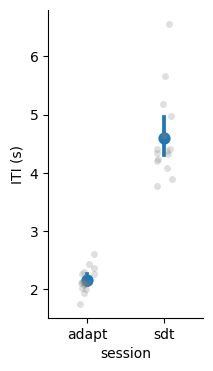

In [6]:
# Calculate inter-trial interval

# ITI = FB onset time to TARGET onset time
# Binary feedback displayed for 1 s
# Endpoint feedback displayed for 0.5 s
df_sdt["ITI"] = 0.5 + df_sdt["click_time"] + df_sdt["ST"].shift(1) + df_sdt["wait_time"] + 1
df_adapt["ITI"] = 0.5 + df_adapt["ST"].shift(1) + df_adapt["wait_time"]

df_iti = pd.concat([df_sdt[["ITI", "SN", "session"]], df_adapt[["ITI", "SN", "session"]]])

fig, ax = plt.subplots(figsize=(2,4))

sns.pointplot(
    data=df_iti.groupby(["SN", "session"], as_index=False)["ITI"].mean(),
    x="session",
    y="ITI",
    errorbar=("ci", 95),
    ls="",
    ax=ax
)
sns.stripplot(
    data=df_iti.groupby(["SN", "session"], as_index=False)["ITI"].mean(),
    x="session",
    y="ITI",
    ax=ax,
    color="grey", alpha=0.25
)




plt.ylabel("ITI (s)")
# ax2.set_xticklabels(["Adapt"])
sns.despine()
plt.show()

In [7]:
results = []

for condition, df in [("SDT", df_sdt), ("Adapt", df_adapt)]:

    # One mean trial duration per subject
    subject_means = df.groupby("SN")["ITI"].mean().to_numpy()

    # Bootstrap 95% CI across subjects
    res = bootstrap(
        (subject_means,),
        lambda x: np.mean(x),
        confidence_level=0.95
    )

    results.append({
        "Condition": condition,
        "Mean": np.mean(subject_means),
        "CI_lower": res.confidence_interval.low,
        "CI_upper": res.confidence_interval.high
    })

df_trial_duration_group = pd.DataFrame(results)

print(df_trial_duration_group.round(3))

# Calculate p
t, p = ttest_ind(
    df_sdt.groupby("SN")["ITI"].mean(),
    df_adapt.groupby("SN")["ITI"].mean(),
    equal_var=False
)

print(f"p = {p:.3f}") if p > 0.001 else print("p < 0.001")

  Condition   Mean  CI_lower  CI_upper
0       SDT  4.607     4.344     5.075
1     Adapt  2.158     2.067     2.260
p < 0.001
